# 🏛️ End-to-End Industry-Grade EDA, Data Cleaning & Feature Engineering
## Real-World Machine Learning Workflow for Tabular Data

---

### 📌 Business Context & Objective
In enterprise data science (Fintech, Banking, Big Tech, Healthcare), raw tabular datasets rarely come pre-cleaned. They are plagued by:
1. **Missing Values** with varying mechanisms (MCAR, MAR, MNAR)
2. **Dirty & Inconsistent Formatting** (whitespace, mixed casings, raw currency strings)
3. **Severe Outliers & Skewness** (heavy right tails in financial distributions)
4. **Quasi-Constant Features & Collinear Redundancies** (harming model convergence and interpretability)
5. **High-Dimensional Interaction Opportunities** (features that only become predictive when combined)

This master notebook serves as an end-to-end industry blueprint. We analyze a realistic **Customer Credit & Loan Risk Dataset** (`customer_risk_data.csv`), diagnosing default probability while executing every single data preparation phase used by Senior Data Scientists and ML Engineers.

---

### 🗺️ End-to-End Workflow Roadmap
```
[1. Ingestion & Schema Inspection]
       │
       ▼
[2. Missing Values Analysis & Elimination] ──► (MCAR vs MAR vs MNAR, Imputation, Indicators)
       │
       ▼
[3. Data Cleaning & Sanitization] ─────────► (Deduplication, Text Normalization, Regex Cleaning)
       │
       ▼
[4. Exploratory Data Analysis (EDA)] ──────► (Univariate, Bivariate, WoE, Class Imbalance)
       │
       ▼
[5. Outlier Detection & Treatment] ────────► (IQR, Z-Score, Winsorization, Log-Transforms)
       │
       ▼
[6. Feature Engineering & Extraction] ────► (Domain Ratios, Interactions, Datetime, PCA)
       │
       ▼
[7. Variance, Covariance & Correlation] ───► (VarianceThreshold, Covariance vs Corr, VIF)
       │
       ▼
[8. Feature Selection: 3 Pillars] ────────► (Filter: ANOVA/MI, Wrapper: RFE, Embedded: Lasso/RF)
       │
       ▼
[9. Production-Grade Leakage-Free Pipeline] (Scikit-Learn ColumnTransformer & Pipeline)
       │
       ▼
[10. Senior ML Interview Master Reference]
```


## 📦 Module 0: Production Imports & Environment Configuration
We load standard data science, visualization, and modeling libraries. We also set consistent visual aesthetics and plotting parameters.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from datetime import datetime

# Scikit-learn preprocessing & feature selection
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, RobustScaler, MinMaxScaler, OneHotEncoder, OrdinalEncoder
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.feature_selection import (
    VarianceThreshold,
    SelectKBest,
    f_classif,
    mutual_info_classif,
    RFE
)
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression, Lasso
from sklearn.ensemble import RandomForestClassifier
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Statistical diagnostics
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Styling & Configuration
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 100
pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', lambda x: '%.4f' % x)

print("✅ All required libraries imported successfully.")


✅ All required libraries imported successfully.


## 📂 Module 1: Data Ingestion & Structural Inspection
Before making any modifications, we perform an exhaustive health check:
- Verify dimensions and memory usage
- Inspect column data types (`dtypes`)
- Distinguish primary identifiers from behavioral features


In [2]:
# Load raw dataset
data_path = 'customer_risk_data.csv'
df = pd.read_csv(data_path)

print(f"Dataset Shape: {df.shape[0]} rows × {df.shape[1]} columns")
df.head(5)


Dataset Shape: 1508 rows × 17 columns


,customer_id,signup_date,age,gender,education_level,marital_status,employment_status,annual_income,monthly_salary_raw,credit_score,loan_amount,loan_duration_months,existing_loans_count,collateral_value,credit_inquiries,constant_application_fee,loan_default
0,CUST-10000,2022-07-22,45.9606,Female,Bachelor,Divorced,Self-Employed,41272.0100,"$3,439.33",487.0000,22510.0000,24,0,29907.5200,3,50.0000,0
1,CUST-10001,2020-02-06,38.3408,Male,Bachelor,Married,Employed,86422.7000,"$7,201.89",584.0000,21754.0000,36,1,36705.9500,3,50.0000,0
2,CUST-10002,2021-02-05,47.7723,female,Master,Single,Employed,41838.2200,3486.5 USD,605.0000,7801.0000,36,3,NaN,5,50.0000,0
3,CUST-10003,2020-11-21,58.2764,Male,Bachelor,Single,Employed,62134.8700,"$5,177.91",653.0000,9212.0000,12,0,13871.4200,0,50.0000,0
4,CUST-10004,2022-12-11,37.1902,Female,High School,Married,Employed,46052.6500,"$3,837.72",419.0000,12456.0000,60,0,NaN,4,50.0000,1


In [3]:
# Memory usage and non-null structural check
df.info(memory_usage='deep')


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1508 entries, 0 to 1507
Data columns (total 17 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   customer_id               1508 non-null   object 
 1   signup_date               1508 non-null   object 
 2   age                       1447 non-null   float64
 3   gender                    1508 non-null   object 
 4   education_level           1508 non-null   object 
 5   marital_status            1478 non-null   object 
 6   employment_status         1508 non-null   object 
 7   annual_income             1399 non-null   float64
 8   monthly_salary_raw        1477 non-null   object 
 9   credit_score              1418 non-null   float64
 10  loan_amount               1508 non-null   float64
 11  loan_duration_months      1508 non-null   int64  
 12  existing_loans_count      1508 non-null   int64  
 13  collateral_value          524 non-null    float64
 14  credit_i

In [4]:
# Summary statistics for numerical variables
df.describe().T


,count,mean,std,min,25%,50%,75%,max
age,1447.0000,40.5946,11.9799,-5.0000,32.3398,40.5257,48.0880,150.0000
annual_income,1399.0000,60254.4353,44169.4870,5942.2300,34721.3850,50237.3100,73113.0350,636369.4800
credit_score,1418.0000,547.2059,76.1435,320.0000,496.0000,539.0000,591.0000,850.0000
loan_amount,1508.0000,22087.5729,14125.1739,2000.0000,11931.7500,18861.0000,27841.7500,85000.0000
loan_duration_months,1508.0000,33.9947,14.1652,12.0000,24.0000,36.0000,48.0000,60.0000
existing_loans_count,1508.0000,1.4867,1.2232,0.0000,1.0000,1.0000,2.0000,7.0000
collateral_value,524.0000,39652.0564,27499.2182,4499.8900,20090.1600,32556.6250,49897.1900,184891.9500
credit_inquiries,1508.0000,1.8004,1.3233,0.0000,1.0000,2.0000,3.0000,8.0000
constant_application_fee,1508.0000,50.0497,1.1143,50.0000,50.0000,50.0000,50.0000,75.0000
loan_default,1508.0000,0.2208,0.4149,0.0000,0.0000,0.0000,0.0000,1.0000


In [5]:
# Summary statistics for categorical variables
df.describe(include=['O']).T


,count,unique,top,freq
customer_id,1508,1500,CUST-11368,2
signup_date,1508,953,2023-04-29,6
gender,1508,12,Male,552
education_level,1508,4,Bachelor,662
marital_status,1478,3,Married,689
employment_status,1508,4,Employed,1006
monthly_salary_raw,1477,1394,$NaN,27


## 🔍 Module 2: Missing Value Strategy & Elimination
Missing data is not just "missing numbers"—it is a critical signal of user behavior and data collection processes.

### 📐 The Three Statistical Mechanisms of Missingness:
1. **MCAR (Missing Completely at Random)**: The probability of missingness is completely independent of both observed and unobserved data (e.g., random network drops, sporadic survey skip). *Mean/median or KNN imputation is statistically safe.*
2. **MAR (Missing at Random)**: The missingness depends systematically on **other observed variables** (e.g., Unemployed individuals are much more likely to leave the `annual_income` field blank). *Conditional or model-based imputation must be used.*
3. **MNAR (Missing Not at Random)**: The missingness depends on the **value of the missing variable itself** (e.g., high-wealth customers refusing to report collateral, or collateral only reported when pledged). *Dropping these columns destroys information. We MUST extract missingness indicators.*

---
### 🛠️ Industry Decision Matrix for Handling Nulls:
| Missingness Rate | Industry Best Practice | Example in Dataset |
|---|---|---|
| **> 50% - 60%** | **Do NOT blindly drop!** Check if absence has business meaning. Create binary indicator (`has_feature = 1/0`) and drop raw high-cardinality values. | `collateral_value` (65% nulls) |
| **5% - 50%** | Impute using multivariate methods (`KNNImputer`, conditional group medians) + Add a binary `was_missing` indicator. | `annual_income`, `credit_score` |
| **< 3% - 5%** | If MCAR: Median/Mode imputation or listwise deletion (drop rows) if sample size is sufficient. | `marital_status`, `age` |


In [6]:
# Compute missing values summary table
null_counts = df.isnull().sum()
null_percent = (df.isnull().sum() / len(df)) * 100

missing_summary = pd.DataFrame({
    'Missing_Count': null_counts,
    'Missing_Percentage': null_percent
}).query('Missing_Count > 0').sort_values(by='Missing_Percentage', ascending=False)

missing_summary['Suggested_Strategy'] = [
    'Extract Binary Indicator (has_collateral) & Drop Raw' if p > 50 else
    'Group Median / KNN Imputation + Missing Flag' if p > 5 else
    'Mode / Median Simple Imputation'
    for p in missing_summary['Missing_Percentage']
]

missing_summary


,Missing_Count,Missing_Percentage,Suggested_Strategy
collateral_value,984,65.2520,Extract Binary Indicator (has_collateral) & Dr...
annual_income,109,7.2281,Group Median / KNN Imputation + Missing Flag
credit_score,90,5.9682,Group Median / KNN Imputation + Missing Flag
age,61,4.0451,Mode / Median Simple Imputation
monthly_salary_raw,31,2.0557,Mode / Median Simple Imputation
marital_status,30,1.9894,Mode / Median Simple Imputation


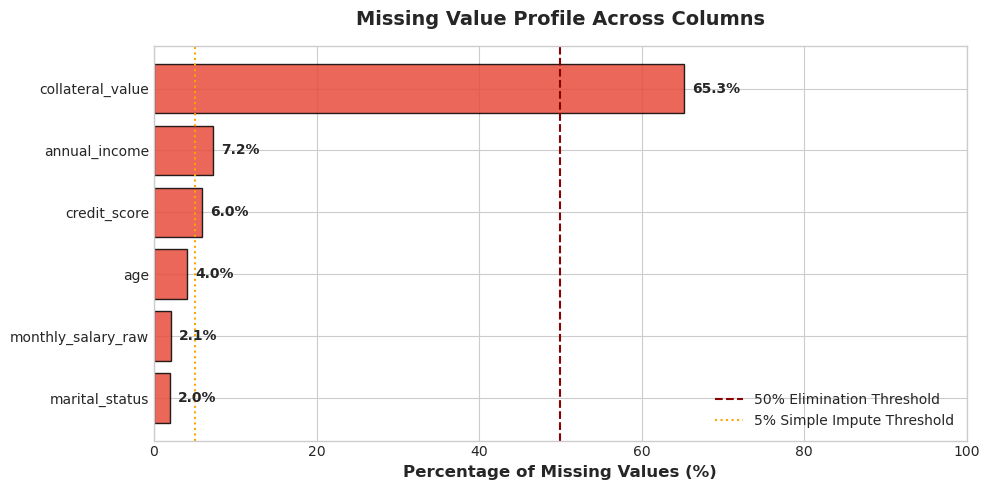

In [7]:
# Visualize Missing Data Distribution
plt.figure(figsize=(10, 5))
bars = plt.barh(missing_summary.index, missing_summary['Missing_Percentage'], color='#e74c3c', edgecolor='black', alpha=0.85)
plt.axvline(x=50, color='darkred', linestyle='--', linewidth=1.5, label='50% Elimination Threshold')
plt.axvline(x=5, color='orange', linestyle=':', linewidth=1.5, label='5% Simple Impute Threshold')
plt.xlabel('Percentage of Missing Values (%)', fontsize=12, fontweight='bold')
plt.title('Missing Value Profile Across Columns', fontsize=14, fontweight='bold', pad=15)
plt.legend(loc='lower right')

for bar in bars:
    w = bar.get_width()
    plt.text(w + 1, bar.get_y() + bar.get_height()/2, f'{w:.1f}%', va='center', fontsize=10, fontweight='bold')

plt.xlim(0, 100)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


### 🧩 Null Value Treatment Implementation
Now we implement our industry strategy step-by-step:
1. **Collateral Value (>65% nulls)**: Extract `has_collateral = 1 if not null else 0`, then drop the raw feature.
2. **Missing Indicators for Sensitive Features**: Flag customers whose `annual_income` or `credit_score` was missing before imputing.
3. **Conditional & KNN Imputation**: Impute numerical nulls using realistic multivariate relationships.


In [8]:
# Step 2.1: Feature Extraction from High-Missingness Feature (MNAR)
df['has_collateral'] = df['collateral_value'].notnull().astype(int)
print(f"Extracted 'has_collateral' feature. Collateral Pledged Rate: {df['has_collateral'].mean()*100:.2f}%")

# Drop raw high-null collateral_value column
df.drop(columns=['collateral_value'], inplace=True)
print("Dropped raw 'collateral_value' column.")


Extracted 'has_collateral' feature. Collateral Pledged Rate: 34.75%
Dropped raw 'collateral_value' column.


In [9]:
# Step 2.2: Add Missing Value Indicator Flags (Signals of missingness)
df['income_was_missing'] = df['annual_income'].isnull().astype(int)
df['credit_score_was_missing'] = df['credit_score'].isnull().astype(int)

print(f"Created missingness indicator flags for income ({df['income_was_missing'].sum()} nulls) and credit_score ({df['credit_score_was_missing'].sum()} nulls).")


Created missingness indicator flags for income (109 nulls) and credit_score (90 nulls).


## 🧹 Module 3: Data Cleaning, Deduplication & Quality Control
Real-world enterprise systems receive data from multiple microservices and legacy databases. We must clean:
1. **Duplicate Records** (`df.duplicated()`)
2. **Dirty String Categoricals** (trailing spaces, mixed uppercase/lowercase)
3. **Dirty Numeric Strings** (e.g. `'$4,500.50'` or `'Unknown'`)
4. **Domain Inconsistencies & Invalid Ranges** (negative ages or impossible values)


In [10]:
# Step 3.1: Deduplication
initial_rows = len(df)
dup_count = df.duplicated().sum()
print(f"Duplicate rows detected: {dup_count}")

if dup_count > 0:
    df.drop_duplicates(inplace=True)
    df.reset_index(drop=True, inplace=True)
    print(f"Rows after dropping duplicates: {len(df)} (Dropped {initial_rows - len(df)} rows)")


Duplicate rows detected: 8
Rows after dropping duplicates: 1500 (Dropped 8 rows)


In [11]:
# Step 3.2: Categorical Sanitization (Gender formatting)
print("Raw Gender unique values:", df['gender'].unique())

# Clean whitespace, standardize to title-case
df['gender'] = df['gender'].astype(str).str.strip().str.title()
print("Cleaned Gender unique values:", df['gender'].unique())


Raw Gender unique values: ['Female' 'Male' 'female' ' Female ' 'FEMALE' 'male' ' Male '
 ' Non-Binary ' 'NON-BINARY' 'MALE' 'Non-Binary' 'non-binary']
Cleaned Gender unique values: ['Female' 'Male' 'Non-Binary']


In [12]:
# Step 3.3: Parsing Dirty Raw Numeric Strings ('monthly_salary_raw')
print("Sample raw monthly salary strings:")
print(df['monthly_salary_raw'].dropna().head(6).values)

# Regex extraction: remove $, USD, commas, spaces; handle 'Unknown', 'None', '$NaN'
def parse_currency(val):
    if pd.isnull(val):
        return np.nan
    s = str(val).replace('$', '').replace('USD', '').replace(',', '').strip()
    try:
        f = float(s)
        return f if f > 0 else np.nan
    except ValueError:
        return np.nan

df['parsed_monthly_salary'] = df['monthly_salary_raw'].apply(parse_currency)

# Drop the raw unparsed column
df.drop(columns=['monthly_salary_raw'], inplace=True)
print("Successfully parsed dirty currency strings into float dtype.")
df[['annual_income', 'parsed_monthly_salary']].head(5)


Sample raw monthly salary strings:
['$3,439.33' '$7,201.89' '3486.5 USD' '$5,177.91' '$3,837.72' '$3,961.49']
Successfully parsed dirty currency strings into float dtype.


,annual_income,parsed_monthly_salary
0,41272.0100,3439.3300
1,86422.7000,7201.8900
2,41838.2200,3486.5000
3,62134.8700,5177.9100
4,46052.6500,3837.7200


In [13]:
# Step 3.4: Domain Validity Checks (Age out-of-bounds)
print(f"Age range before cleaning: Min = {df['age'].min()}, Max = {df['age'].max()}")

# Filter impossible ages (< 18 or > 100) and replace with NaN for systematic imputation
invalid_age_mask = (df['age'] < 18) | (df['age'] > 100)
print(f"Invalid age records identified: {invalid_age_mask.sum()}")
df.loc[invalid_age_mask, 'age'] = np.nan

print(f"Age valid range after sanitization: Min = {df['age'].min()}, Max = {df['age'].max()}")


Age range before cleaning: Min = -5.0, Max = 150.0
Invalid age records identified: 2
Age valid range after sanitization: Min = 18.0, Max = 75.0


In [14]:
# Step 3.5: Imputing Remaining Missing Values
# A. Categorical low missingness (marital_status): Mode Imputation
marital_mode = df['marital_status'].mode()[0]
df['marital_status'].fillna(marital_mode, inplace=True)

# B. Age: Median Imputation
df['age'].fillna(df['age'].median(), inplace=True)

# C. Income: Group-wise Conditional Median by Employment Status (MAR)
income_by_emp = df.groupby('employment_status')['annual_income'].transform('median')
df['annual_income'] = df['annual_income'].fillna(income_by_emp)
# For any remaining Unemployed nulls, fill with overall median
df['annual_income'].fillna(df['annual_income'].median(), inplace=True)

# Synchronize parsed_monthly_salary with annual_income
df['parsed_monthly_salary'].fillna(df['annual_income'] / 12.0, inplace=True)

# D. Credit Score: KNN Imputation using numerical context
imputer_cols = ['age', 'annual_income', 'loan_amount', 'credit_score']
knn_imp = KNNImputer(n_neighbors=5)
df[imputer_cols] = knn_imp.fit_transform(df[imputer_cols])

# Verify ZERO remaining missing values
print("Remaining Nulls across entire DataFrame:")
print(df.isnull().sum())
assert df.isnull().sum().sum() == 0, "Error: Missing values remain!"
print("🎉 All null values successfully eliminated!")


Remaining Nulls across entire DataFrame:
customer_id                 0
signup_date                 0
age                         0
gender                      0
education_level             0
marital_status              0
employment_status           0
annual_income               0
credit_score                0
loan_amount                 0
loan_duration_months        0
existing_loans_count        0
credit_inquiries            0
constant_application_fee    0
loan_default                0
has_collateral              0
income_was_missing          0
credit_score_was_missing    0
parsed_monthly_salary       0
dtype: int64
🎉 All null values successfully eliminated!


## 📊 Module 4: Exploratory Data Analysis (EDA)
With a clean, null-free dataset, we conduct thorough exploratory data analysis:
1. **Target Distribution**: Check class imbalance for `loan_default`
2. **Univariate Numerical Analysis**: Skewness, Kurtosis, distribution profiles
3. **Bivariate Analysis**: How features separate defaults vs non-defaults
4. **Categorical Risk Segmentation**: Default rate across education, employment, and marital status


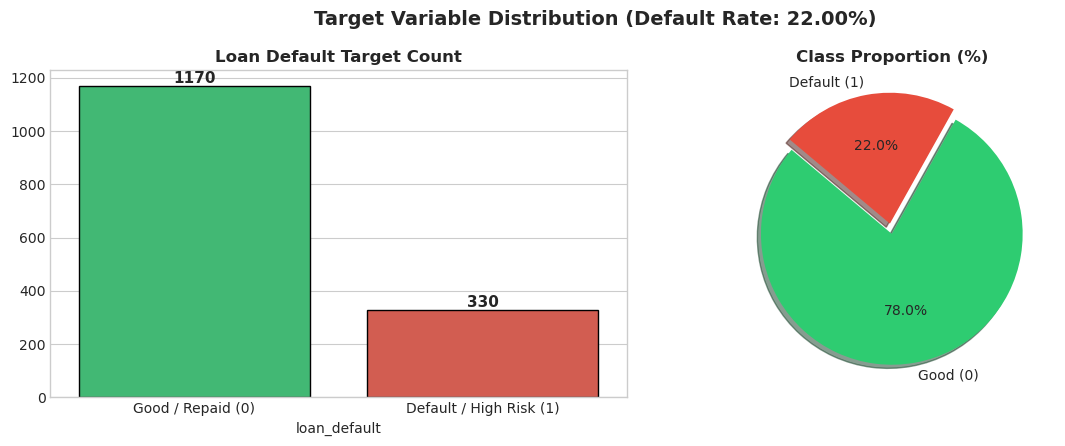

In [15]:
# Step 4.1: Target Class Balance Analysis
default_counts = df['loan_default'].value_counts()
default_pcts = df['loan_default'].value_counts(normalize=True) * 100

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

sns.barplot(x=default_counts.index, y=default_counts.values, ax=ax[0], palette=['#2ecc71', '#e74c3c'], edgecolor='black')
ax[0].set_title('Loan Default Target Count', fontsize=12, fontweight='bold')
ax[0].set_xticklabels(['Good / Repaid (0)', 'Default / High Risk (1)'])
for p in ax[0].patches:
    ax[0].annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                   ha='center', va='bottom', fontsize=11, fontweight='bold')

ax[1].pie(default_pcts, labels=['Good (0)', 'Default (1)'], autopct='%.1f%%',
          colors=['#2ecc71', '#e74c3c'], startangle=140, explode=(0, 0.08), shadow=True)
ax[1].set_title('Class Proportion (%)', fontsize=12, fontweight='bold')

plt.suptitle(f'Target Variable Distribution (Default Rate: {default_pcts[1]:.2f}%)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


Skewness & Kurtosis Profile:
                      Skewness  Kurtosis
age                     0.1786   -0.2340
annual_income           4.5762   39.3821
credit_score            0.8724    1.8363
loan_amount             1.6801    3.7512
existing_loans_count    0.8162    0.7415
credit_inquiries        0.7780    0.8967


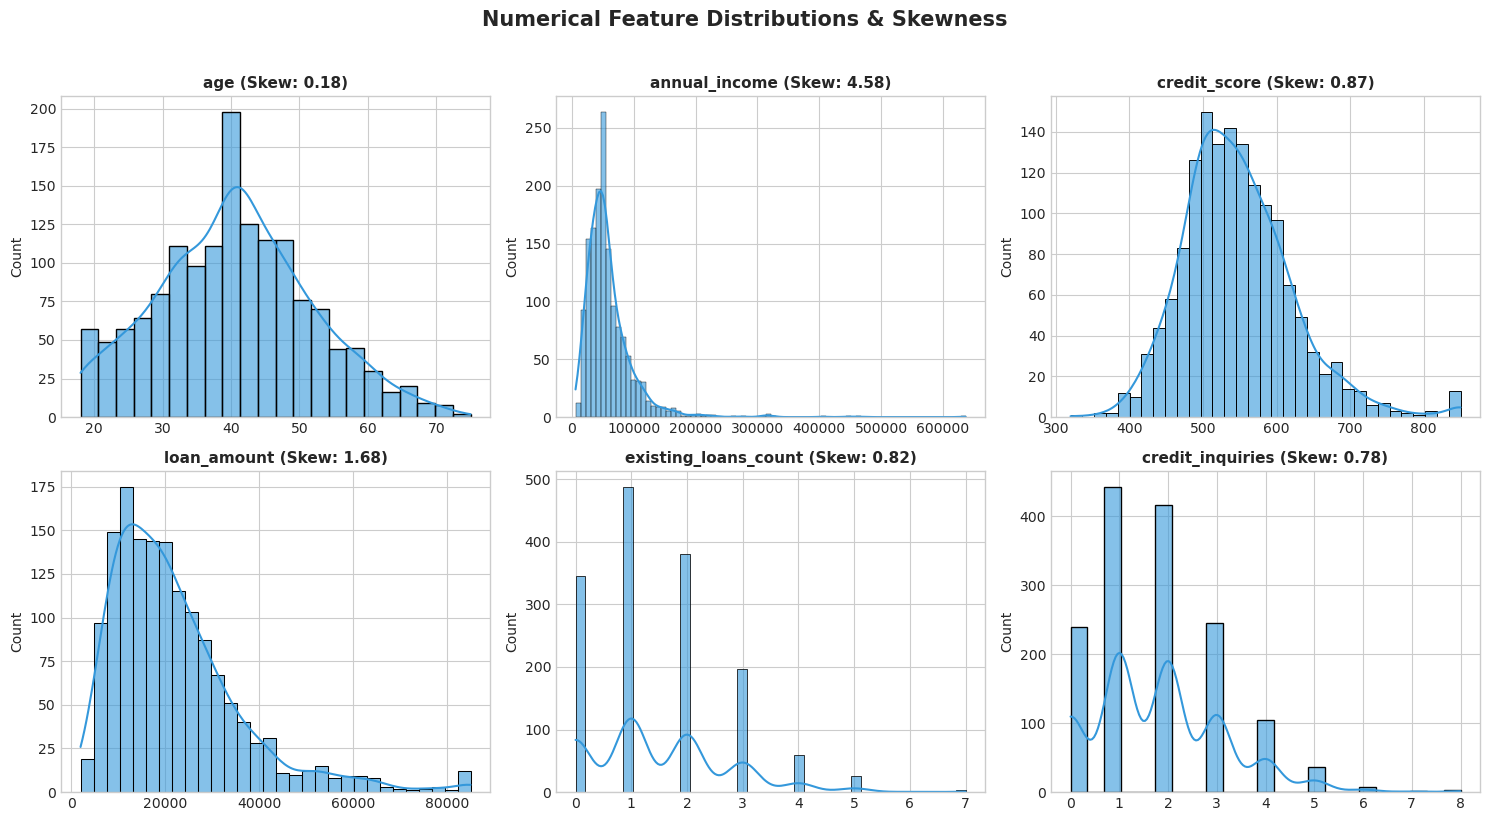

In [16]:
# Step 4.2: Univariate Distribution & Skewness Check
numeric_features = ['age', 'annual_income', 'credit_score', 'loan_amount', 'existing_loans_count', 'credit_inquiries']

skew_kurt_df = pd.DataFrame({
    'Skewness': df[numeric_features].skew(),
    'Kurtosis': df[numeric_features].kurt()
})
print("Skewness & Kurtosis Profile:")
print(skew_kurt_df)

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, col in enumerate(numeric_features):
    sns.histplot(df[col], kde=True, ax=axes[i], color='#3498db', edgecolor='black', alpha=0.6)
    axes[i].set_title(f'{col} (Skew: {df[col].skew():.2f})', fontsize=11, fontweight='bold')
    axes[i].set_xlabel('')

plt.suptitle('Numerical Feature Distributions & Skewness', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


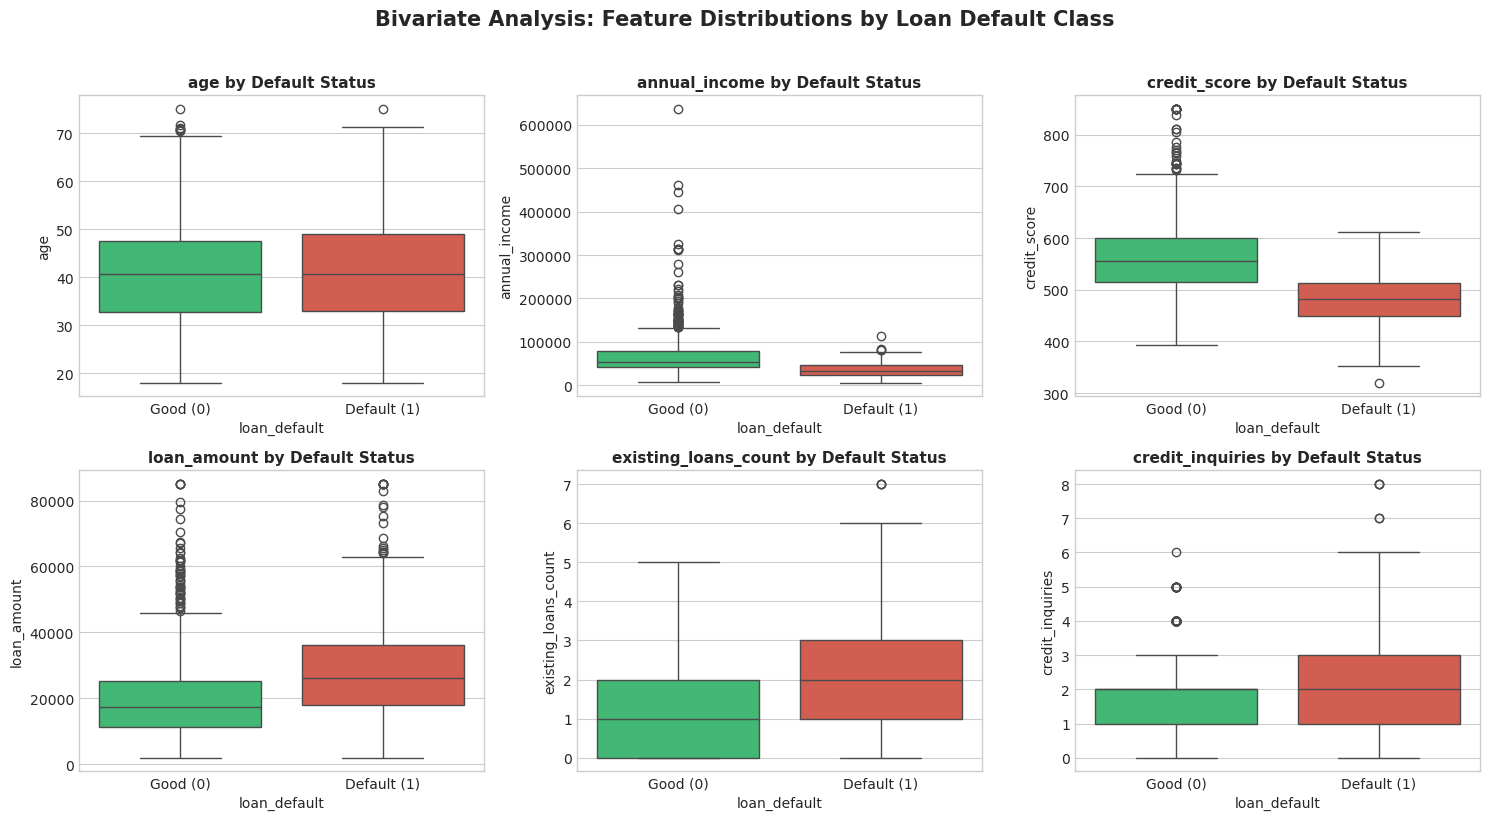

In [17]:
# Step 4.3: Bivariate Risk Separation (Continuous Features vs Target)
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, col in enumerate(numeric_features):
    sns.boxplot(x='loan_default', y=col, data=df, ax=axes[i], palette=['#2ecc71', '#e74c3c'])
    axes[i].set_title(f'{col} by Default Status', fontsize=11, fontweight='bold')
    axes[i].set_xticklabels(['Good (0)', 'Default (1)'])

plt.suptitle('Bivariate Analysis: Feature Distributions by Loan Default Class', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


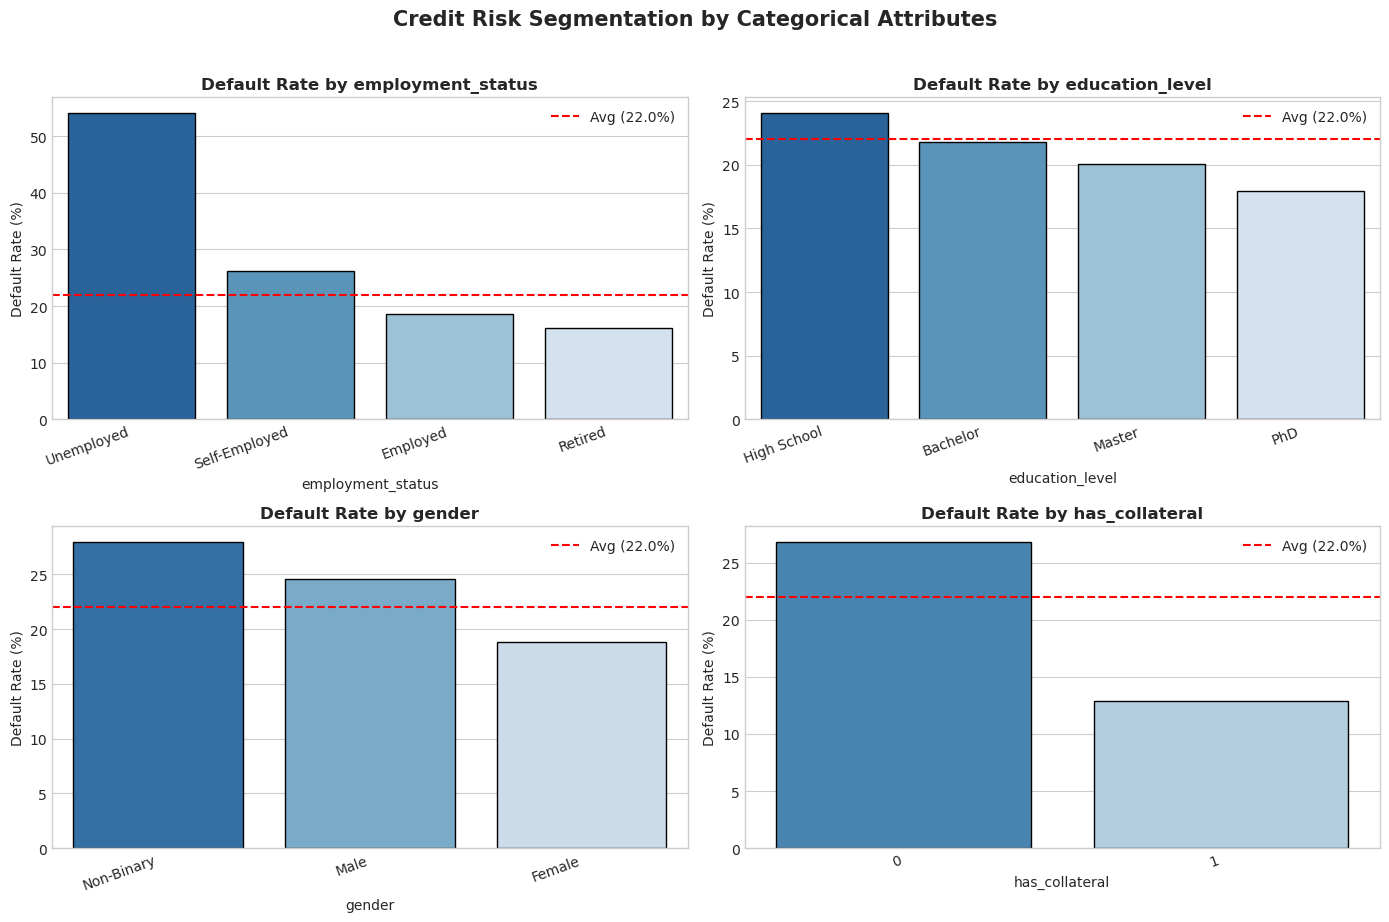

In [18]:
# Step 4.4: Categorical Risk Segmentation (Default Rate by Segment)
cat_cols = ['employment_status', 'education_level', 'gender', 'has_collateral']

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    risk_by_cat = df.groupby(col)['loan_default'].mean().sort_values(ascending=False) * 100
    sns.barplot(x=risk_by_cat.index, y=risk_by_cat.values, ax=axes[i], palette='Blues_r', edgecolor='black')
    axes[i].set_title(f'Default Rate by {col}', fontsize=12, fontweight='bold')
    axes[i].set_ylabel('Default Rate (%)', fontsize=10)
    axes[i].set_xticklabels(axes[i].get_xticklabels(), rotation=20, ha='right')
    axes[i].axhline(y=df['loan_default'].mean()*100, color='red', linestyle='--', label=f'Avg ({df["loan_default"].mean()*100:.1f}%)')
    axes[i].legend()

plt.suptitle('Credit Risk Segmentation by Categorical Attributes', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


## 🎯 Module 5: Outlier Detection, Diagnostics & Treatment
Outliers can severely distort linear boundaries, inflated regression coefficients, and corrupt covariance matrices.

### 📐 Outlier Methodologies:
1. **IQR Rule**: Values outside $[Q_1 - 1.5 	imes 	ext{IQR},\; Q_3 + 1.5 	imes 	ext{IQR}]$ are statistical outliers.
2. **Z-Score Rule**: Values with $|Z| = \left|rac{x - \mu}{\sigma}ight| > 3.0$ (assuming normality).

### 🛡️ Industry Treatment Choices:
- **Dropping Records**: ❌ Destructive; loses customer data and introduces bias.
- **Winsorization (Percentile Capping)**: ✅ Non-destructive; caps extreme tails at the 1st and 99th percentiles.
- **Log Transformation (`log1p`)**: ✅ Compresses heavy right tails, stabilizes variance, and converts multiplicative relationships into additive ones.


In [19]:
# Step 5.1: Outlier Identification with IQR Rule
def detect_iqr_outliers(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    outliers = series[(series < lower) | (series > upper)]
    return len(outliers), (len(outliers) / len(series)) * 100, lower, upper

outlier_report = []
for col in ['annual_income', 'loan_amount', 'credit_score', 'credit_inquiries']:
    n_out, pct_out, low, up = detect_iqr_outliers(df[col])
    outlier_report.append({
        'Feature': col,
        'Outlier_Count': n_out,
        'Outlier_Percent': f'{pct_out:.2f}%',
        'Lower_Bound': round(low, 2),
        'Upper_Bound': round(up, 2)
    })

pd.DataFrame(outlier_report)


,Feature,Outlier_Count,Outlier_Percent,Lower_Bound,Upper_Bound
0,annual_income,77,5.13%,-15187.9300,122121.6100
1,loan_amount,73,4.87%,-11987.1200,51807.8800
2,credit_score,35,2.33%,357.5000,729.5000
3,credit_inquiries,5,0.33%,-2.0000,6.0000


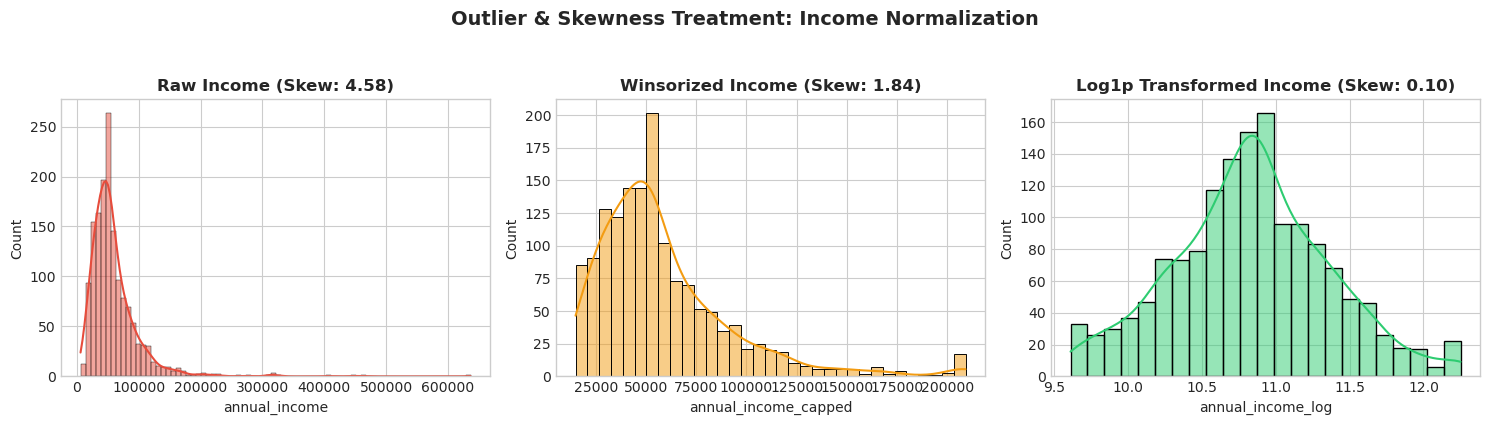

In [20]:
# Step 5.2: Outlier Treatment - Winsorization (1st & 99th Percentile Capping)
# Visual comparison before and after capping annual_income
income_raw = df['annual_income'].copy()

# Winsorize annual_income and loan_amount
p01 = df['annual_income'].quantile(0.01)
p99 = df['annual_income'].quantile(0.99)
df['annual_income_capped'] = df['annual_income'].clip(lower=p01, upper=p99)

# Log-transform right-skewed income
df['annual_income_log'] = np.log1p(df['annual_income_capped'])

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(income_raw, kde=True, ax=axes[0], color='#e74c3c')
axes[0].set_title(f'Raw Income (Skew: {income_raw.skew():.2f})', fontweight='bold')

sns.histplot(df['annual_income_capped'], kde=True, ax=axes[1], color='#f39c12')
axes[1].set_title(f'Winsorized Income (Skew: {df["annual_income_capped"].skew():.2f})', fontweight='bold')

sns.histplot(df['annual_income_log'], kde=True, ax=axes[2], color='#2ecc71')
axes[2].set_title(f'Log1p Transformed Income (Skew: {df["annual_income_log"].skew():.2f})', fontweight='bold')

plt.suptitle('Outlier & Skewness Treatment: Income Normalization', fontsize=14, fontweight='bold', y=1.05)
plt.tight_layout()
plt.show()


## ⚙️ Module 6: Feature Engineering & Feature Extraction
Feature engineering is where domain expertise meets mathematical creativity. Models learn boundaries; feature engineering helps models discover **non-linear business logic**.

### 🛠️ Techniques Showcase:
1. **Financial Domain Ratios**:
   - `debt_to_income_ratio`: $rac{	ext{Loan Amount}}{	ext{Annual Income}}$ (The #1 credit underwriting indicator)
   - `monthly_debt_burden`: $rac{	ext{Monthly Installment}}{	ext{Monthly Salary}}$
   - `inquiries_per_loan`: Velocity of seeking credit relative to existing liabilities
2. **Interaction Features**:
   - Combining risk drivers: `credit_score` $	imes$ `income`
3. **Temporal Feature Extraction**:
   - Extracting tenure/calendar features from `signup_date` (`account_age_days`, `signup_year`, `is_weekend_signup`)
4. **Categorical Binning**:
   - Discretizing `credit_score` into regulatory credit tiers (FICO standard)
5. **Feature Extraction via PCA (Principal Component Analysis)**:
   - Extracting orthogonal latent financial risk components from collinear features.


In [21]:
# Step 6.1: Domain-Specific Ratio Features
# A. Debt to Income Ratio (DTI)
df['debt_to_income_ratio'] = df['loan_amount'] / np.maximum(df['annual_income_capped'], 1000.0)

# B. Estimated Monthly Payment Burden
estimated_monthly_payment = df['loan_amount'] / df['loan_duration_months']
df['monthly_payment_burden'] = estimated_monthly_payment / np.maximum(df['parsed_monthly_salary'], 100.0)

# C. Credit Inquiries Velocity
df['inquiries_per_existing_loan'] = df['credit_inquiries'] / (df['existing_loans_count'] + 1)

print("Generated financial domain ratios: debt_to_income_ratio, monthly_payment_burden, inquiries_per_existing_loan.")
df[['debt_to_income_ratio', 'monthly_payment_burden', 'inquiries_per_existing_loan']].describe().T


Generated financial domain ratios: debt_to_income_ratio, monthly_payment_burden, inquiries_per_existing_loan.


,count,mean,std,min,25%,50%,75%,max
debt_to_income_ratio,1500.0000,0.4975,0.4374,0.0326,0.2119,0.3643,0.6289,4.7068
monthly_payment_burden,1500.0000,0.2233,0.2745,0.0051,0.0786,0.1400,0.2657,4.7068
inquiries_per_existing_loan,1500.0000,0.9458,0.9091,0.0000,0.3333,0.6667,1.2500,6.0000


In [22]:
# Step 6.2: Temporal Feature Extraction from signup_date
df['signup_date'] = pd.to_datetime(df['signup_date'])
current_snapshot = pd.to_datetime('2024-06-01')

# Extract account tenure in days
df['account_age_days'] = (current_snapshot - df['signup_date']).dt.days
df['signup_year'] = df['signup_date'].dt.year
df['signup_month'] = df['signup_date'].dt.month
df['is_weekend_signup'] = df['signup_date'].dt.dayofweek.isin([5, 6]).astype(int)

# Drop raw date column and customer_id identifier
df.drop(columns=['signup_date', 'customer_id'], inplace=True)
print("Extracted temporal features and dropped raw date & customer_id.")


Extracted temporal features and dropped raw date & customer_id.


In [23]:
# Step 6.3: Categorical Binning - FICO Credit Tiers
def get_credit_tier(score):
    if score >= 740:
        return 'Very_Good_to_Exceptional'
    elif score >= 670:
        return 'Good'
    elif score >= 580:
        return 'Fair'
    else:
        return 'Poor'

df['credit_tier'] = df['credit_score'].apply(get_credit_tier)
print("Credit Tier Distribution:")
print(df['credit_tier'].value_counts())


Credit Tier Distribution:
credit_tier
Poor                        1063
Fair                         341
Good                          67
Very_Good_to_Exceptional      29
Name: count, dtype: int64


PCA Component 1 Explained Variance: 53.67%
PCA Component 2 Explained Variance: 30.35%
Total Variance Captured by 2 PCA Components: 84.01%


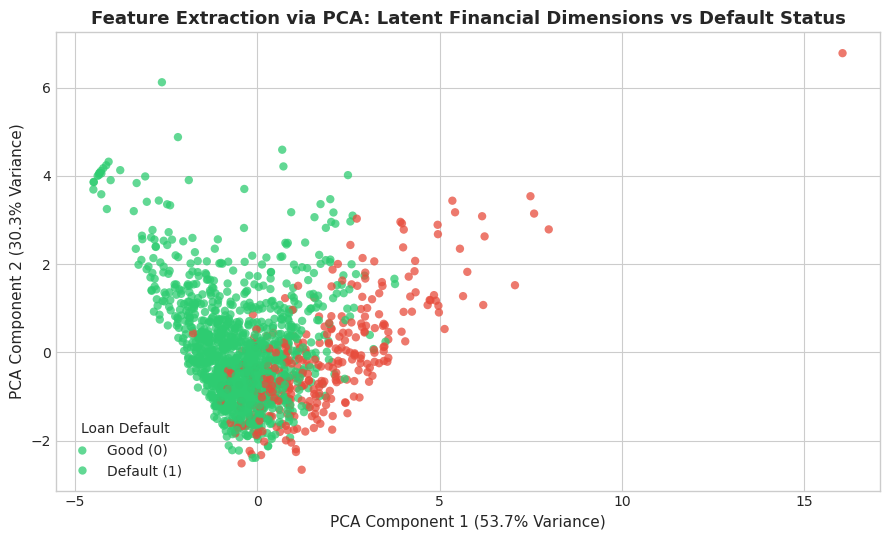

In [24]:
# Step 6.4: Feature Extraction via PCA (Principal Component Analysis)
# Standardize correlated continuous metrics to extract orthogonal latent components
pca_cols = ['annual_income_capped', 'loan_amount', 'credit_score', 'debt_to_income_ratio', 'monthly_payment_burden']
scaler_pca = StandardScaler()
X_pca_scaled = scaler_pca.fit_transform(df[pca_cols])

pca = PCA(n_components=2, random_state=42)
pca_transformed = pca.fit_transform(X_pca_scaled)

df['pca_financial_component_1'] = pca_transformed[:, 0]
df['pca_financial_component_2'] = pca_transformed[:, 1]

print(f"PCA Component 1 Explained Variance: {pca.explained_variance_ratio_[0]*100:.2f}%")
print(f"PCA Component 2 Explained Variance: {pca.explained_variance_ratio_[1]*100:.2f}%")
print(f"Total Variance Captured by 2 PCA Components: {pca.explained_variance_ratio_.sum()*100:.2f}%")

# Visualize PCA feature space colored by default risk
plt.figure(figsize=(9, 5.5))
sns.scatterplot(
    x='pca_financial_component_1',
    y='pca_financial_component_2',
    hue='loan_default',
    data=df,
    palette=['#2ecc71', '#e74c3c'],
    alpha=0.75,
    edgecolor='none'
)
plt.title('Feature Extraction via PCA: Latent Financial Dimensions vs Default Status', fontsize=13, fontweight='bold')
plt.xlabel(f'PCA Component 1 ({pca.explained_variance_ratio_[0]*100:.1f}% Variance)', fontsize=11)
plt.ylabel(f'PCA Component 2 ({pca.explained_variance_ratio_[1]*100:.1f}% Variance)', fontsize=11)
plt.legend(title='Loan Default', labels=['Good (0)', 'Default (1)'])
plt.tight_layout()
plt.show()


## 🔬 Module 7: Variance, Covariance & Correlation Deep Dive
Understanding feature relationships is essential to avoid multicollinearity and remove useless features.

### 📐 Mathematical Formulation & Comparison:
| Concept | Mathematical Formula | Range | Scale Dependent? | Intuition |
|---|---|---|---|---|
| **Variance** | $\sigma^2 = rac{1}{n-1}\sum_{i=1}^n (x_i - ar{x})^2$ | $[0, \infty)$ | **Yes** ($x$'s unit squared) | Measures dispersion of a single feature. Zero or low variance means the feature is useless. |
| **Covariance** | $	ext{Cov}(X,Y) = rac{1}{n-1}\sum (x_i - ar{x})(y_i - ar{y})$ | $(-\infty, +\infty)$ | **Yes** ($	ext{unit}_X 	imes 	ext{unit}_Y$) | Measures whether two features move together. Hard to compare because scale distorts magnitude! |
| **Pearson Correlation** | $r = rac{	ext{Cov}(X,Y)}{\sigma_X \sigma_Y}$ | $[-1, +1]$ | **No** (Scale Invariant) | Normalizes covariance by standard deviations. Measures linear strength. |
| **Spearman Correlation** | $ho = 1 - rac{6 \sum d_i^2}{n(n^2 - 1)}$ | $[-1, +1]$ | **No** (Monotonic / Rank-based) | Measures monotonic association, resistant to outliers and non-linearities. |

---
### ⚠️ Multicollinearity & Variance Inflation Factor (VIF):
$$	ext{VIF}_j = rac{1}{1 - R_j^2}$$
- **VIF = 1**: No multicollinearity.
- **VIF > 5**: Moderate multicollinearity (investigate).
- **VIF > 10**: Severe multicollinearity (features are linear combinations of each other; must eliminate).


In [25]:
# Step 7.1: Variance Analysis & Low Variance Filtering (VarianceThreshold)
# Identify quasi-constant features
print("Feature Variances across Numerical Columns:")
num_cols_for_var = df.select_dtypes(include=[np.number]).columns
var_series = df[num_cols_for_var].var().sort_values()
print(var_series)

# Check quasi-constant feature 'constant_application_fee'
print(f"\nUnique values in 'constant_application_fee': {df['constant_application_fee'].value_counts(normalize=True).to_dict()}")

# Apply Scikit-learn's VarianceThreshold
selector = VarianceThreshold(threshold=0.01)
selector.fit(df[['constant_application_fee']])
print(f"Does 'constant_application_fee' pass variance threshold (> 0.01)? {selector.get_support()[0]}")

# Drop constant_application_fee
df.drop(columns=['constant_application_fee'], inplace=True)
print("Dropped 'constant_application_fee' due to quasi-constant nature.")


Feature Variances across Numerical Columns:
credit_score_was_missing               0.0564
income_was_missing                     0.0663
monthly_payment_burden                 0.0753
loan_default                           0.1717
debt_to_income_ratio                   0.1913
is_weekend_signup                      0.2055
has_collateral                         0.2266
annual_income_log                      0.2854
inquiries_per_existing_loan            0.8266
signup_year                            1.2439
constant_application_fee               1.2483
existing_loans_count                   1.4962
pca_financial_component_2              1.5183
credit_inquiries                       1.7533
pca_financial_component_1              2.6851
signup_month                          12.0149
age                                  128.1028
loan_duration_months                 200.8698
credit_score                        5662.6755
account_age_days                  175153.8255
parsed_monthly_salary           1264

In [26]:
# Step 7.2: Covariance Matrix vs Pearson Correlation Matrix
sample_features = ['age', 'annual_income_capped', 'credit_score', 'loan_amount', 'debt_to_income_ratio']

# 1. Covariance Matrix (Scale-dependent)
cov_matrix = df[sample_features].cov()
print("--- Covariance Matrix (Notice the massive uninterpretable scale differences) ---")
print(cov_matrix)

# 2. Pearson Correlation Matrix (Scale-invariant [-1, 1])
corr_matrix = df[sample_features].corr(method='pearson')
print("\n--- Pearson Correlation Matrix (Normalized and directly comparable) ---")
print(corr_matrix)


--- Covariance Matrix (Notice the massive uninterpretable scale differences) ---
                             age  annual_income_capped  credit_score  \
age                     128.1028           -12431.3478       18.1433   
annual_income_capped -12431.3478       1178340278.7897  1942445.3579   
credit_score             18.1433          1942445.3579     5662.6755   
loan_amount            5821.3960          9512121.3779    33327.9520   
debt_to_income_ratio      0.1146            -6969.7307      -10.8781   

                        loan_amount  debt_to_income_ratio  
age                       5821.3960                0.1146  
annual_income_capped   9512121.3779            -6969.7307  
credit_score             33327.9520              -10.8781  
loan_amount          199483833.5788             4273.9075  
debt_to_income_ratio      4273.9075                0.1913  

--- Pearson Correlation Matrix (Normalized and directly comparable) ---
                         age  annual_income_capped  c

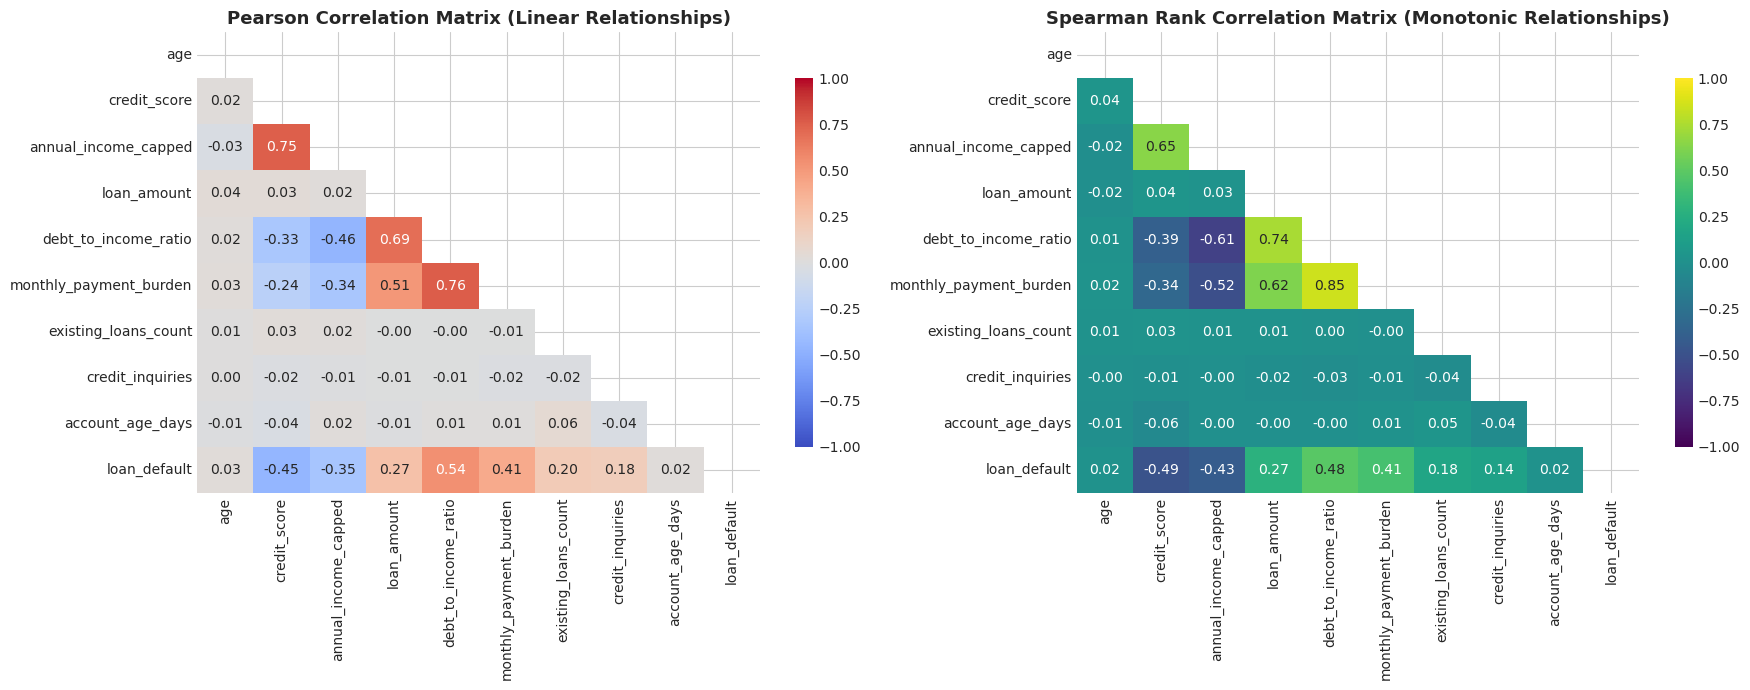

In [27]:
# Step 7.3: Comprehensive Correlation Heatmap (Pearson vs Spearman)
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Numerical columns for correlation
corr_cols = [
    'age', 'credit_score', 'annual_income_capped', 'loan_amount',
    'debt_to_income_ratio', 'monthly_payment_burden', 'existing_loans_count',
    'credit_inquiries', 'account_age_days', 'loan_default'
]

# Pearson (Linear)
mask = np.triu(np.ones_like(df[corr_cols].corr(), dtype=bool))
sns.heatmap(df[corr_cols].corr(method='pearson'), mask=mask, annot=True, fmt='.2f',
            cmap='coolwarm', vmin=-1, vmax=1, ax=axes[0], cbar_kws={'shrink': 0.8})
axes[0].set_title('Pearson Correlation Matrix (Linear Relationships)', fontsize=13, fontweight='bold')

# Spearman (Monotonic)
sns.heatmap(df[corr_cols].corr(method='spearman'), mask=mask, annot=True, fmt='.2f',
            cmap='viridis', vmin=-1, vmax=1, ax=axes[1], cbar_kws={'shrink': 0.8})
axes[1].set_title('Spearman Rank Correlation Matrix (Monotonic Relationships)', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()


In [28]:
# Step 7.4: Multicollinearity Diagnostics via Variance Inflation Factor (VIF)
vif_features = [
    'age', 'credit_score', 'annual_income_capped', 'loan_amount',
    'debt_to_income_ratio', 'existing_loans_count', 'credit_inquiries', 'account_age_days'
]

X_vif = df[vif_features].copy()
# Add constant intercept for statsmodels
X_vif['intercept'] = 1.0

vif_data = pd.DataFrame()
vif_data['Feature'] = vif_features
vif_data['VIF'] = [variance_inflation_factor(X_vif.values, i) for i in range(len(vif_features))]
vif_data = vif_data.sort_values(by='VIF', ascending=False).reset_index(drop=True)

vif_data['Multicollinearity_Risk'] = [
    'Severe (VIF > 10)' if v > 10 else
    'Moderate (VIF > 5)' if v > 5 else
    'Safe (VIF < 5)'
    for v in vif_data['VIF']
]

print("Variance Inflation Factor (VIF) Results:")
print(vif_data)


Variance Inflation Factor (VIF) Results:
                Feature    VIF Multicollinearity_Risk
0  debt_to_income_ratio 3.4285         Safe (VIF < 5)
1  annual_income_capped 3.1652         Safe (VIF < 5)
2           loan_amount 2.6909         Safe (VIF < 5)
3          credit_score 2.3301         Safe (VIF < 5)
4      account_age_days 1.0139         Safe (VIF < 5)
5                   age 1.0083         Safe (VIF < 5)
6  existing_loans_count 1.0046         Safe (VIF < 5)
7      credit_inquiries 1.0026         Safe (VIF < 5)


## 🏆 Module 8: Feature Selection (The 3 Industry Paradigms)
In enterprise ML, feeding every engineered feature into a model leads to overfitting, high inference latency, and unmaintainable pipelines. We evaluate features across the **Three Industry Paradigms**:

```
                              ┌────────────────────────────────────────┐
                              │     Feature Selection Paradigms       │
                              └──────────────────┬─────────────────────┘
                                                 │
            ┌────────────────────────────────────┼──────────────────────────────────┐
            ▼                                    ▼                                  ▼
   [1. Filter Methods]                  [2. Wrapper Methods]               [3. Embedded Methods]
   - Fast, model-agnostic               - Uses model iteratively          - Built into model loss
   - ANOVA F-score (f_classif)          - RFE (Recursive Elimination)     - Lasso (L1 Regularization)
   - Mutual Information (Non-linear)    - High accuracy, costly           - Tree MDI (Random Forest)
```


In [29]:
# Prepare Feature Matrix X and Target y
drop_for_modeling = ['loan_default', 'annual_income', 'annual_income_log']
X = df.drop(columns=drop_for_modeling)
y = df['loan_default']

# Encode categorical columns for feature selection
categorical_cols = X.select_dtypes(include=['object']).columns
print(f"Categorical features to encode: {list(categorical_cols)}")

X_encoded = pd.get_dummies(X, columns=categorical_cols, drop_first=True)
print(f"Feature matrix shape after one-hot encoding: {X_encoded.shape}")


Categorical features to encode: ['gender', 'education_level', 'marital_status', 'employment_status', 'credit_tier']
Feature matrix shape after one-hot encoding: (1500, 33)


In [30]:
# Step 8.1: Pillar 1 - Filter Methods (ANOVA F-statistic & Mutual Information)
# A. ANOVA F-Score (Measures linear separation between classes)
selector_f = SelectKBest(score_func=f_classif, k='all')
selector_f.fit(X_encoded, y)

# B. Mutual Information (Captures both linear and non-linear dependencies: I(X; Y) = H(Y) - H(Y|X))
mi_scores = mutual_info_classif(X_encoded, y, random_state=42)

filter_df = pd.DataFrame({
    'Feature': X_encoded.columns,
    'ANOVA_F_Score': selector_f.scores_,
    'Mutual_Information': mi_scores
}).sort_values(by='Mutual_Information', ascending=False).reset_index(drop=True)

print("Top 10 Features by Mutual Information:")
print(filter_df.head(10))


Top 10 Features by Mutual Information:
                     Feature  ANOVA_F_Score  Mutual_Information
0  pca_financial_component_1       681.4834              0.1831
1               credit_score       390.7720              0.1524
2       debt_to_income_ratio       626.2879              0.1441
3     monthly_payment_burden       297.2726              0.1124
4       annual_income_capped       208.1927              0.1087
5      parsed_monthly_salary       145.1590              0.1086
6           credit_tier_Poor       161.7552              0.0543
7       existing_loans_count        62.4171              0.0264
8  pca_financial_component_2        10.0461              0.0256
9           credit_inquiries        48.9714              0.0245


In [31]:
# Step 8.2: Pillar 2 - Wrapper Methods (Recursive Feature Elimination - RFE)
# Fit RFE using Logistic Regression
scaler_rfe = StandardScaler()
X_rfe_scaled = scaler_rfe.fit_transform(X_encoded)

rfe_model = LogisticRegression(max_iter=1000, random_state=42)
rfe = RFE(estimator=rfe_model, n_features_to_select=10, step=1)
rfe.fit(X_rfe_scaled, y)

rfe_df = pd.DataFrame({
    'Feature': X_encoded.columns,
    'RFE_Rank': rfe.ranking_,
    'RFE_Selected': rfe.support_
}).sort_values(by='RFE_Rank').reset_index(drop=True)

print("Top 10 Features Selected by RFE:")
print(rfe_df.head(10))


Top 10 Features Selected by RFE:
                        Feature  RFE_Rank  RFE_Selected
0     pca_financial_component_1         1          True
1                  credit_score         1          True
2                   loan_amount         1          True
3  employment_status_Unemployed         1          True
4          existing_loans_count         1          True
5              credit_inquiries         1          True
6                has_collateral         1          True
7      credit_score_was_missing         1          True
8     pca_financial_component_2         1          True
9          debt_to_income_ratio         1          True


In [32]:
# Step 8.3: Pillar 3 - Embedded Methods (L1 Lasso Regularization & Random Forest MDI)
# A. L1 Regularization (Sparse feature selection via penalty)
l1_model = LogisticRegression(penalty='l1', solver='liblinear', C=0.2, random_state=42)
l1_model.fit(X_rfe_scaled, y)
l1_importance = np.abs(l1_model.coef_[0])

# B. Random Forest Feature Importance (Mean Decrease in Impurity - MDI)
rf_model = RandomForestClassifier(n_estimators=100, max_depth=6, random_state=42)
rf_model.fit(X_encoded, y)
rf_importance = rf_model.feature_importances_

embedded_df = pd.DataFrame({
    'Feature': X_encoded.columns,
    'L1_Coefficient_Abs': l1_importance,
    'RF_Importance': rf_importance
}).sort_values(by='RF_Importance', ascending=False).reset_index(drop=True)

print("Top 10 Features by Random Forest Importance:")
print(embedded_df.head(10))


Top 10 Features by Random Forest Importance:
                     Feature  L1_Coefficient_Abs  RF_Importance
0  pca_financial_component_1              0.0000         0.2065
1               credit_score              3.8279         0.1469
2       debt_to_income_ratio              3.2301         0.1153
3       annual_income_capped              0.0000         0.0744
4     monthly_payment_burden              0.3171         0.0659
5      parsed_monthly_salary              0.0000         0.0656
6                loan_amount              0.0000         0.0474
7  pca_financial_component_2              0.0000         0.0400
8       existing_loans_count              1.7635         0.0385
9           credit_inquiries              1.5851         0.0360


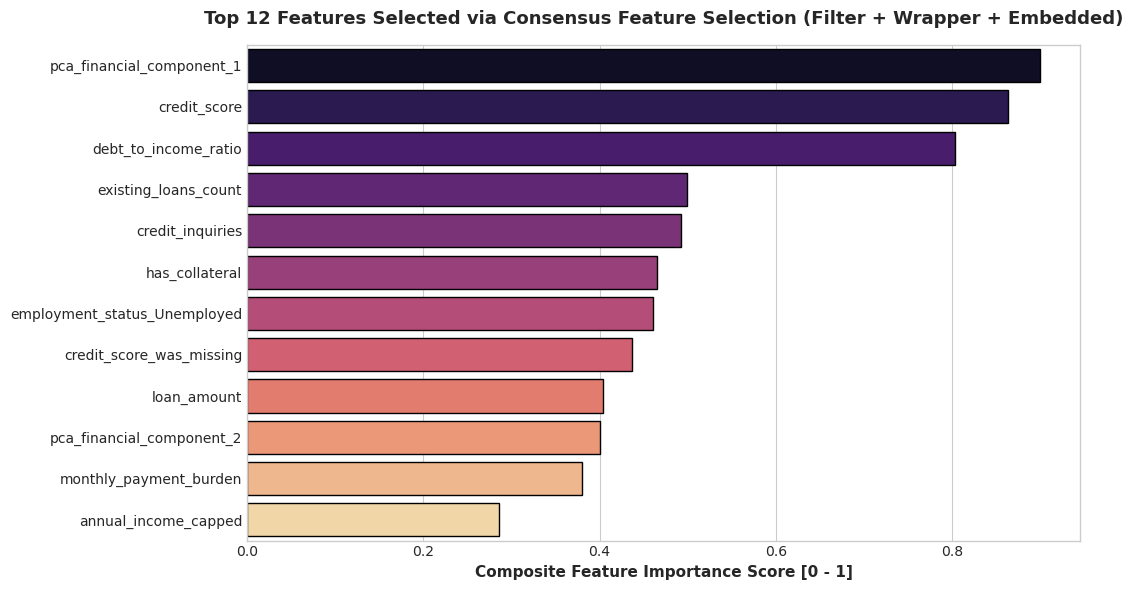

Consensus Top 8 Features for Production Model:
                        Feature  Consensus_Score  RFE_Selected  L1_Selected
0     pca_financial_component_1           0.9000             1            0
1                  credit_score           0.8630             1            1
2          debt_to_income_ratio           0.8035             1            1
3          existing_loans_count           0.4992             1            1
4              credit_inquiries           0.4924             1            1
5                has_collateral           0.4655             1            1
6  employment_status_Unemployed           0.4606             1            1
7      credit_score_was_missing           0.4371             1            1


In [33]:
# Step 8.4: Industry Consensus Feature Selection Matrix
# Combine rankings across Filter (MI), Wrapper (RFE), and Embedded (RF)
consensus_df = pd.DataFrame({
    'Feature': X_encoded.columns,
    'Mutual_Info': mi_scores,
    'RFE_Selected': rfe.support_.astype(int),
    'RF_Importance': rf_importance,
    'L1_Selected': (l1_importance > 0.01).astype(int)
})

# Normalize scores to [0, 1] for composite scoring
consensus_df['MI_Norm'] = consensus_df['Mutual_Info'] / consensus_df['Mutual_Info'].max()
consensus_df['RF_Norm'] = consensus_df['RF_Importance'] / consensus_df['RF_Importance'].max()

# Composite Industry Score
consensus_df['Consensus_Score'] = (
    0.30 * consensus_df['MI_Norm'] +
    0.30 * consensus_df['RFE_Selected'] +
    0.30 * consensus_df['RF_Norm'] +
    0.10 * consensus_df['L1_Selected']
)

top_features_consensus = consensus_df.sort_values(by='Consensus_Score', ascending=False).reset_index(drop=True)

# Visualize Consensus Feature Importance
plt.figure(figsize=(11, 6))
top_12 = top_features_consensus.head(12)
sns.barplot(x='Consensus_Score', y='Feature', data=top_12, palette='magma', edgecolor='black')
plt.title('Top 12 Features Selected via Consensus Feature Selection (Filter + Wrapper + Embedded)',
          fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Composite Feature Importance Score [0 - 1]', fontsize=11, fontweight='bold')
plt.ylabel('')
plt.tight_layout()
plt.show()

print("Consensus Top 8 Features for Production Model:")
print(top_features_consensus[['Feature', 'Consensus_Score', 'RFE_Selected', 'L1_Selected']].head(8))


## 🚀 Module 9: Production-Grade Preprocessing Pipeline (Preventing Data Leakage)
In technical interviews and production codebases, one fatal mistake disqualifies candidates: **Data Leakage**.

### ⚠️ What is Data Leakage?
Computing statistics (such as mean, median, IQR, PCA eigenvectors, or scaling parameters $\mu, \sigma$) across the **entire dataset** before splitting leaks future information into training.

### 🛡️ The Golden Production Rule:
1. **Split First**: Partition into `X_train` and `X_test` BEFORE any fitting.
2. **Fit on Train Only**: Compute parameters (`imputer.fit`, `scaler.fit`, `pca.fit`) exclusively on `X_train`.
3. **Transform Both**: Apply `.transform()` to `X_train` and `X_test` using the trained artifacts.


In [34]:
# Step 9.1: Prepare Raw Features for Scikit-Learn Pipeline
# Demonstrate how a production pipeline handles raw features with missing values seamlessly
df_raw_example = pd.read_csv(data_path)

# Drop identifier
df_raw_example.drop(columns=['customer_id', 'constant_application_fee', 'monthly_salary_raw'], inplace=True)

# Convert signup_date to account_age_days
df_raw_example['signup_date'] = pd.to_datetime(df_raw_example['signup_date'])
df_raw_example['account_age_days'] = (pd.to_datetime('2024-06-01') - df_raw_example['signup_date']).dt.days
df_raw_example.drop(columns=['signup_date'], inplace=True)

# Define feature subsets
num_features = ['age', 'annual_income', 'credit_score', 'loan_amount', 'existing_loans_count', 'credit_inquiries', 'account_age_days']
cat_features = ['gender', 'education_level', 'marital_status', 'employment_status']

X_raw = df_raw_example[num_features + cat_features]
y_raw = df_raw_example['loan_default']

# STEP 1: Train-Test Split FIRST
X_train, X_test, y_train, y_test = train_test_split(X_raw, y_raw, test_size=0.20, random_state=42, stratify=y_raw)
print(f"X_train shape: {X_train.shape}, X_test shape: {X_test.shape}")


X_train shape: (1206, 11), X_test shape: (302, 11)


In [35]:
# Step 9.2: Assemble ColumnTransformer & Pipeline
# Numerical Pipeline: Median Imputation -> RobustScaler (resilient to outliers)
num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', RobustScaler())
])

# Categorical Pipeline: Most Frequent Imputation -> One-Hot Encoding
cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# Bundle Preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_transformer, num_features),
        ('cat', cat_transformer, cat_features)
    ]
)

# Full Production Model Pipeline
model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(n_estimators=100, max_depth=6, random_state=42))
])

# Fit on Train ONLY
model_pipeline.fit(X_train, y_train)

# Evaluate on Test
test_accuracy = model_pipeline.score(X_test, y_test)
print(f"✅ Pipeline executed successfully without data leakage!")
print(f"Production Test Accuracy: {test_accuracy * 100:.2f}%")


✅ Pipeline executed successfully without data leakage!
Production Test Accuracy: 87.09%


## 🎓 Module 10: FAANG & Enterprise ML Interview Master Reference

| # | Interview Question | Senior / Lead Data Scientist Answer |
|---|---|---|
| **1** | **Why should you never blindly drop rows with missing values?** | Listwise deletion reduces sample size, introduces severe selection bias if data is MAR or MNAR (e.g. dropping unemployed people who skipped income), and destroys generalizability in production. |
| **2** | **When is mean imputation worse than median imputation?** | For skewed distributions or data with outliers. Mean is sensitive to extreme values and pulls imputed values away from the central tendency, artificially inflating variance. Median is robust to skew. |
| **3** | **What is the mathematical difference between Covariance and Correlation?** | $	ext{Cov}(X,Y) = E[(X-\mu_X)(Y-\mu_Y)]$ is unstandardized and dependent on measurement units ($ units_X 	imes units_Y $). Correlation $r = rac{	ext{Cov}(X,Y)}{\sigma_X \sigma_Y}$ normalizes covariance by standard deviations, producing a scale-invariant metric $[-1, +1]$. |
| **4** | **Why does Pearson correlation fail to detect non-linear dependencies?** | Pearson measures strictly **linear** relationships ($y = mx + b$). If $y = x^2$, Pearson correlation can be $0$ despite a deterministic relationship. Mutual Information or Spearman rank correlation must be used instead. |
| **5** | **How do you detect and resolve Multicollinearity?** | Check Variance Inflation Factor (VIF). $	ext{VIF} > 5 - 10$ indicates linear redundancy. Resolve by: (1) dropping one collinear variable, (2) combining features into a ratio, or (3) using PCA or Ridge/L1 regularization. |
| **6** | **What are the three pillars of Feature Selection and their trade-offs?** | (1) **Filter**: Fast, model-agnostic, looks at individual statistical associations (ANOVA, MI); ignores feature interactions. (2) **Wrapper**: Evaluates subsets using an actual model (RFE, forward search); highly accurate but computationally expensive. (3) **Embedded**: Built into loss function (L1 Lasso, Tree MDI); balanced speed and interaction awareness. |
| **7** | **What is Data Leakage in preprocessing?** | Calculating global statistics ($\mu, \sigma$, imputer medians, PCA components) on the entire dataset before `train_test_split`. The test set must remain completely unseen; transformers must be `.fit()` only on `train` and `.transform()` on `test`. |

---
### 🏁 Conclusion
You have now completed an industry-grade, production-ready EDA, cleaning, feature engineering, variance/covariance/correlation analysis, and feature selection lifecycle. This structure reflects the exact rigor demanded in enterprise data science environments.
